# Arbitrary SED photometry with ArgusSim

This notebook teaches the complete path from sampled wavelength/flux arrays to
**synthetic AB magnitudes**, **filter-transmitted photons/s**, and **full-system
detected electrons/s**, then uses the electron rates directly in `NoiseBudget`.

We use ten real stellar SEDs from five MESA tracks (0.8, 1, 3, 5, and 10 M☉),
spanning about 3,201–22,726 K. The CSV decoding is specific to these demonstration
inputs; the `ABPhot` API is generic and accepts any caller-loaded Quantity arrays.

Plots, displayed tables and text label the two Argus bands β and ρ; the code and the
stored tables use the band keys `"beta"` and `"rho"`.

**Run:** The ten input files are in the adjacent `demo_SED_data/` folder.
Plots, tables, and validation results are stored inline.

## 1. Import the API and choose the observation

Load only the filters we need. `SystemThroughput` supplies the filter curves,
optics, detector QE, and atmosphere; `ABPhot` uses the telescope collecting area
and the existing **AB zero point** (`ab.zp_ergs`). Set the distance below to explore
how flux and magnitude change. Distance scaling belongs in the caller.

In [1]:
from pathlib import Path
import csv
import hashlib
import re

import astropy.units as u
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from argus_sim import ABPhot, NoiseBudget, SystemThroughput
from argus_sim.spectral_sky import build_band_params, signal_throughput

%matplotlib inline

data_dir = Path("demo_SED_data")
if not data_dir.is_dir():
    data_dir = Path("notebooks/demo_SED_data")
assert data_dir.is_dir(), "Run from the repository root or notebooks/ directory."

INPUT_DISTANCE_PC = 10.0
DISTANCE_PC = 1000.0
COMPARISON_BETA_AB = 20.0
FLAM = u.erg / (u.s * u.cm**2 * u.AA)
BANDS = ("beta", "rho")
COLORS = {"beta": "#2878b5", "rho": "#ce593b"}
BAND_LABEL = {"beta": "β", "rho": "ρ"}
tp = SystemThroughput(filters={band: True for band in BANDS})
ab = ABPhot(throughput=tp)
bp = build_band_params(BANDS, tp, ab)
print(f"Collecting area: {ab.collecting_area.to(u.cm**2):.3f}")
print(f"AB zero-point Fν: {ab.zp_ergs.to(u.Jy):.6f}")

2026-10-27 02:35:59,713 — argus_sim — INFO — <module>:51 — No configuration file found, proceeding with defaults.


AB zero-point Fν: 3630.780548 Jy


## 2. Understand the raw files and selected models

The bundled CSVs contain `wavelengths` in
**Angstrom** and `fluxes` in **erg s⁻¹ cm⁻² Å⁻¹**, already scaled to **10 pc**.
The flux already includes stellar-radius scaling: do not apply it again.
`G_SED_...csv` contains the full SED, not just its Gaia G-band portion. Ignore
`convolved_flux`, `filter_wavelengths`, and `filter_trans`: those contain a
previous filter calculation, while we want to integrate the raw source spectrum
through the Argus filters ourselves.

Per track, the main-sequence sample has central hydrogen closest to 0.35 while
hydrogen burning supplies more than 95% of luminosity. The evolved sample is the
coolest available model with central hydrogen below 0.001. These are a snapshot
of the available runs; the solar-mass track was still running when copied.
Mass labels give the **initial** track mass, not the current mass after mass loss.
The 0.8 M☉ track has [M/H] = −2; the others have [M/H] = 0.

All input files are bundled in `demo_SED_data/` beside this notebook.
The cells below use relative paths to that folder. Model metadata and
SHA-256 hashes are included below; no external data directory is needed.

In [2]:
sample_metadata = [
    {'label': 'S01', 'file': 'M00.80_MH-2.0_a1.98_sed__G_SED_00000265.csv', 'sha256': 'f0ca70dd45d717376be4b1d657f4b7f653e1f99b8f88bee2fbeb109292deae28', 'track': 'M00.80_MH-2.0_a1.98_sed', 'model_number': 265, 'state': 'MS', 'initial_mass_msun': 0.8, 'teff_K': 6405.184949066382, 'log_g': 4.512271864316389, 'star_age_yr': 5694923419.848505, 'center_h1': 0.344755616052035},
    {'label': 'S02', 'file': 'M00.80_MH-2.0_a1.98_sed__G_SED_00005132.csv', 'sha256': '26ee6300572ded6c7d68428744bd7ce91ff68b9a4a2bd3aa6d673d631d32234d', 'track': 'M00.80_MH-2.0_a1.98_sed', 'model_number': 5132, 'state': 'cool evolved', 'initial_mass_msun': 0.8, 'teff_K': 4170.53385667105, 'log_g': 0.45324437495665376, 'star_age_yr': 12290839742.280954, 'center_h1': 0.0},
    {'label': 'S03', 'file': 'M01.00_MH+0.0_a1.98_sed__G_SED_00000267.csv', 'sha256': 'e8063b784e5254efdd2771f9d6a9097df40b65ad651b0a4844ea4185c6fede97', 'track': 'M01.00_MH+0.0_a1.98_sed', 'model_number': 267, 'state': 'MS', 'initial_mass_msun': 1.0, 'teff_K': 5779.32200424775, 'log_g': 4.429014303709752, 'star_age_yr': 4887186316.388706, 'center_h1': 0.3485165031838796},
    {'label': 'S04', 'file': 'M01.00_MH+0.0_a1.98_sed__G_SED_00009793.csv', 'sha256': 'f74be6f3ad9713c0e32418ed43df9c7c0b0f242b4919b643607b103dc26162e6', 'track': 'M01.00_MH+0.0_a1.98_sed', 'model_number': 9793, 'state': 'cool evolved', 'initial_mass_msun': 1.0, 'teff_K': 3200.922401848937, 'log_g': -0.00028028239818344533, 'star_age_yr': 12451312964.769312, 'center_h1': 0.0},
    {'label': 'S05', 'file': 'M03.00_MH+0.0_a1.98_sed__G_SED_00000331.csv', 'sha256': '0fbbbbb53ac8be61752e59b98c4e1210769601323310cfe4111d143772764a3c', 'track': 'M03.00_MH+0.0_a1.98_sed', 'model_number': 331, 'state': 'MS', 'initial_mass_msun': 3.0, 'teff_K': 10799.144229359694, 'log_g': 3.943780279674499, 'star_age_yr': 266104501.33950222, 'center_h1': 0.35124399712957893},
    {'label': 'S06', 'file': 'M03.00_MH+0.0_a1.98_sed__G_SED_00000577.csv', 'sha256': 'a1dce96ffc17acbd50a5bbf62e568df9f4676a68213a21c82f02b17211d2e2d4', 'track': 'M03.00_MH+0.0_a1.98_sed', 'model_number': 577, 'state': 'cool evolved', 'initial_mass_msun': 3.0, 'teff_K': 4362.0658924678055, 'log_g': 1.740305959353508, 'star_age_yr': 385475871.0999133, 'center_h1': 0.0},
    {'label': 'S07', 'file': 'M05.00_MH+0.0_a1.98_sed__G_SED_00000341.csv', 'sha256': 'f3cec964eed31e50dff5aa24a21e8ef31e780b37a5fe8bfc0fa8246d9711e447', 'track': 'M05.00_MH+0.0_a1.98_sed', 'model_number': 341, 'state': 'MS', 'initial_mass_msun': 5.0, 'teff_K': 15220.344960893377, 'log_g': 3.9064971423698123, 'star_age_yr': 75904039.9739883, 'center_h1': 0.34556059342018314},
    {'label': 'S08', 'file': 'M05.00_MH+0.0_a1.98_sed__G_SED_00000596.csv', 'sha256': '42d411567d251ee808f02d90b1efa7835eaccd140965452155e8e5bd372aff96', 'track': 'M05.00_MH+0.0_a1.98_sed', 'model_number': 596, 'state': 'cool evolved', 'initial_mass_msun': 5.0, 'teff_K': 4122.957212478633, 'log_g': 1.1869769730679236, 'star_age_yr': 105619795.81774774, 'center_h1': 0.0},
    {'label': 'S09', 'file': 'M10.00_MH+0.0_a1.98_sed__G_SED_00000344.csv', 'sha256': '7d537c123edf1a7bd4107e599222f259eed2d3ed441472829eb308372a4dd43a', 'track': 'M10.00_MH+0.0_a1.98_sed', 'model_number': 344, 'state': 'MS', 'initial_mass_msun': 10.0, 'teff_K': 22725.512050069163, 'log_g': 3.8686782046312707, 'star_age_yr': 17737805.696489632, 'center_h1': 0.34505078870439865},
    {'label': 'S10', 'file': 'M10.00_MH+0.0_a1.98_sed__G_SED_00000647.csv', 'sha256': 'e29813c2205b53550f9449da6a8af80dc6b43047daab92fda3b5934d4d0d3daf', 'track': 'M10.00_MH+0.0_a1.98_sed', 'model_number': 647, 'state': 'cool evolved', 'initial_mass_msun': 10.0, 'teff_K': 3719.379748482785, 'log_g': 0.3146655014335994, 'star_age_yr': 24872485.870877735, 'center_h1': 0.0},
]

model_table = pd.DataFrame(sample_metadata)
display(model_table[["label", "initial_mass_msun", "state", "model_number", "teff_K", "log_g", "track"]].round({"teff_K": 0, "log_g": 3}))

,label,initial_mass_msun,state,model_number,teff_K,log_g,track
0,S01,0.8,MS,265,6405.0,4.512,M00.80_MH-2.0_a1.98_sed
1,S02,0.8,cool evolved,5132,4171.0,0.453,M00.80_MH-2.0_a1.98_sed
2,S03,1.0,MS,267,5779.0,4.429,M01.00_MH+0.0_a1.98_sed
3,S04,1.0,cool evolved,9793,3201.0,-0.000,M01.00_MH+0.0_a1.98_sed
4,S05,3.0,MS,331,10799.0,3.944,M03.00_MH+0.0_a1.98_sed
5,S06,3.0,cool evolved,577,4362.0,1.740,M03.00_MH+0.0_a1.98_sed
6,S07,5.0,MS,341,15220.0,3.906,M05.00_MH+0.0_a1.98_sed
7,S08,5.0,cool evolved,596,4123.0,1.187,M05.00_MH+0.0_a1.98_sed
8,S09,10.0,MS,344,22726.0,3.869,M10.00_MH+0.0_a1.98_sed
9,S10,10.0,cool evolved,647,3719.0,0.315,M10.00_MH+0.0_a1.98_sed


## 3. Load the CSV into physical Quantity arrays

The small reader below is the only format-specific part. It handles Fortran's
three-digit exponents with an omitted `E` (for example `1.180971-100`) and removes
zero-wavelength padding rows. The physical SED sampling is preserved.

For another data source, replace this reader with your own loader that returns
1D wavelength and Fλ or Fν arrays with units (including Jy). `ABPhot` converts
with Astropy spectral-density equivalencies, sorts wavelengths, rejects invalid
or duplicate samples, and interpolates on `SystemThroughput.wav`.

Full non-zero filter support is required by default. For intentional incomplete
coverage, pass `allow_partial=True`; uncovered wavelengths then contribute zero,
so that result is a partial-band measurement. We use full coverage throughout.

In [3]:
def load_csv(path):
    """Decode the raw CSV's first two columns and remove zero padding.

    These demo CSVs use the Fortran
    convention that drops E in three-digit exponents, e.g. 1.180971-100.
    The other CSV columns already contain filter information and are unused.
    """
    rows = []
    with path.open() as stream:
        reader = csv.DictReader(stream)
        for row in reader:
            values = [float(re.sub(r"(?<=\d)([+-]\d{3})\b", r"E\1", row[key].strip()))
                      for key in ("wavelengths", "fluxes")]
            if values[0] != 0:
                rows.append(values)
    wave, flux = np.asarray(rows).T
    return wave * u.AA, flux * FLAM

## 4. Run one SED through all three methods

The input flux represents the observer-frame source **above the atmosphere**.
Scale from 10 pc to the chosen distance with $(10\,{\rm pc}/d)^2$ before calling
the API. No extra radius scaling, extinction, or redshift is applied here.

`photons_from_sed` integrates $A\int F_\lambda R_{\rm filter}/E_{\rm photon}\,d\lambda$.
`mag_from_sed` calibrates that filter-only photon rate with `mag_from_photons`
and the existing AB zero point. It integrates the SED rather than evaluating it
at an effective wavelength. The MESA history's Vega magnitudes are not used.

`electrons_from_sed` keeps filter × optics × QE × atmosphere$^{\rm airmass}$ ×
grey transparency inside the integral. Its electron/s Quantity goes directly
into `NoiseBudget.get_snr` as the source rate.

In [4]:
first = sample_metadata[0]
wavelength, flux_at_10pc = load_csv(data_dir / first["file"])
flux = flux_at_10pc * (INPUT_DISTANCE_PC / DISTANCE_PC)**2

single_source = []
for band in BANDS:
    photons = ab.photons_from_sed(band, wavelength, flux)
    magnitude = ab.mag_from_sed(band, wavelength, flux)
    electrons = ab.electrons_from_sed(
        band, wavelength, flux, airmass=1.2, transparency=0.8,
    )
    single_source.append({"band": band, "mag_AB": float(magnitude),
                          "filter_photons/s": photons.to_value(u.photon / u.s),
                          "detected_electrons/s": electrons.to_value(u.electron / u.s)})
display(pd.DataFrame(single_source).replace({"band": BAND_LABEL}).round(3))

,band,mag_AB,filter_photons/s,detected_electrons/s
0,β,15.167,685.450,254.049
1,ρ,14.753,1015.895,270.749


## 5. Calculate the ten-source photometry table

Here the same API processes every source in both filters. We retain the original
luminosity differences at the chosen distance and make a second set of flux
arrays normalized to **β = 20 AB** for comparison at equal brightness. The latter
is a mathematical comparison, not a new physical distance or stellar model;
the spectra keep their shapes and therefore their β − ρ colors.

Photon rates include collecting area and the filter. Electron rates also include
optics, QE, and atmosphere. The main table uses airmass 1 and transparency 1.
The auxiliary `photometry` DataFrame retains rates at airmass 2 and the normalized
comparison rates. The wavelength coverage, unit-equivalence, grey-factor, and
magnitude assertions run for all 20 source-band combinations.

In [5]:
samples, results = [], []
airmasses = np.linspace(0, 3, 61)
unit_errors, grey_errors = [], []
for i, item in enumerate(sample_metadata):
    path = data_dir / item["file"]
    assert hashlib.sha256(path.read_bytes()).hexdigest() == item["sha256"]
    wave, flux10 = load_csv(path)
    # These CSV fluxes already include radius and the 10 pc dilution.
    # Rescale once here; do not apply any extra stellar-radius factor.
    flux = flux10 * (INPUT_DISTANCE_PC / DISTANCE_PC) ** 2  # illustrative observer at 1 kpc
    label = f"S{i + 1:02d}"
    gmag = float(ab.mag_from_sed("beta", wave, flux))
    flux20 = flux * 10 ** (-0.4 * (COMPARISON_BETA_AB - gmag))
    sample = dict(item, label=label, wave=wave, flux=flux, flux20=flux20, rates={})
    for band in BANDS:
        photons = ab.photons_from_sed(band, wave, flux)
        mag = float(ab.mag_from_sed(band, wave, flux))
        electrons = ab.electrons_from_sed(band, wave, flux, airmass=1.0)
        fnu = flux.to(u.Jy, equivalencies=u.spectral_density(wave))
        converted = ab.electrons_from_sed(band, wave, fnu, airmass=1.0)
        error = abs((converted / electrons).value - 1)
        unit_errors.append(error)
        assert error < 1e-12
        grey = ab.electrons_from_sed(band, wave, flux, transparency=0.73)
        grey_error = abs((grey / electrons).value - 0.73)
        grey_errors.append(grey_error)
        assert grey_error < 1e-12
        assert abs(float(ab.mag_from_photons(band, photons)) - mag) < 1e-12
        assert abs(float(ab.mag_from_sed(band, wave, flux20)) -
                   (mag + COMPARISON_BETA_AB - gmag)) < 1e-10
        sample["rates"][band] = np.array([
            ab.electrons_from_sed(band, wave, flux, airmass=float(x)).value
            for x in airmasses
        ])
        results.append(dict(
            sample=label, track=item["track"], model_number=item["model_number"],
            state=item["state"], teff_K=item["teff_K"], log_g=item["log_g"],
            band=band, distance_pc=DISTANCE_PC, mag_ab_10pc=mag - 5 * np.log10(DISTANCE_PC / INPUT_DISTANCE_PC), mag_ab_at_distance=mag,
            photons_per_s=photons.to_value(u.photon / u.s),
            electrons_per_s_am1=electrons.to_value(u.electron / u.s),
            electrons_per_s_am2=sample["rates"][band][40],
            electrons_per_s_comparison_am1=ab.electrons_from_sed(band, wave, flux20).value,
            efficiency_am1=electrons.value / photons.value,
        ))
    samples.append(sample)

photometry = pd.DataFrame(results)
display(photometry[["sample", "band", "mag_ab_10pc", "mag_ab_at_distance",
                    "photons_per_s", "electrons_per_s_am1", "efficiency_am1"]]
        .replace({"band": BAND_LABEL}).round(3))

,sample,band,mag_ab_10pc,mag_ab_at_distance,photons_per_s,electrons_per_s_am1,efficiency_am1
0,S01,β,5.167,15.167,6.854500e+02,334.463,0.488
1,S01,ρ,4.753,14.753,1.015895e+03,347.009,0.342
2,S02,β,-1.430,8.570,2.983150e+05,164862.761,0.553
3,S02,ρ,-3.402,6.598,1.856736e+06,585871.192,0.316
4,S03,β,5.329,15.329,5.899520e+02,302.098,0.512
5,S03,ρ,4.560,14.560,1.213635e+03,411.070,0.339
6,S04,β,-0.471,9.529,1.233022e+05,69674.690,0.565
7,S04,ρ,-3.276,6.724,1.654393e+06,462353.630,0.279
8,S05,β,-0.081,9.919,8.609791e+04,41090.210,0.477
9,S05,ρ,0.289,10.289,6.201896e+04,22430.924,0.362


## 6. Compare spectra with the Argus bandpasses

The upper panel shows flux at the chosen distance. The lower panel compares
spectral shapes at equal β AB magnitude and overlays the filter curves.
Fλ is converted to Fν only for presentation; the API integrates the physical
SED through each band. Both panels use logarithmic flux axes so hot and cool
stars remain visible together.

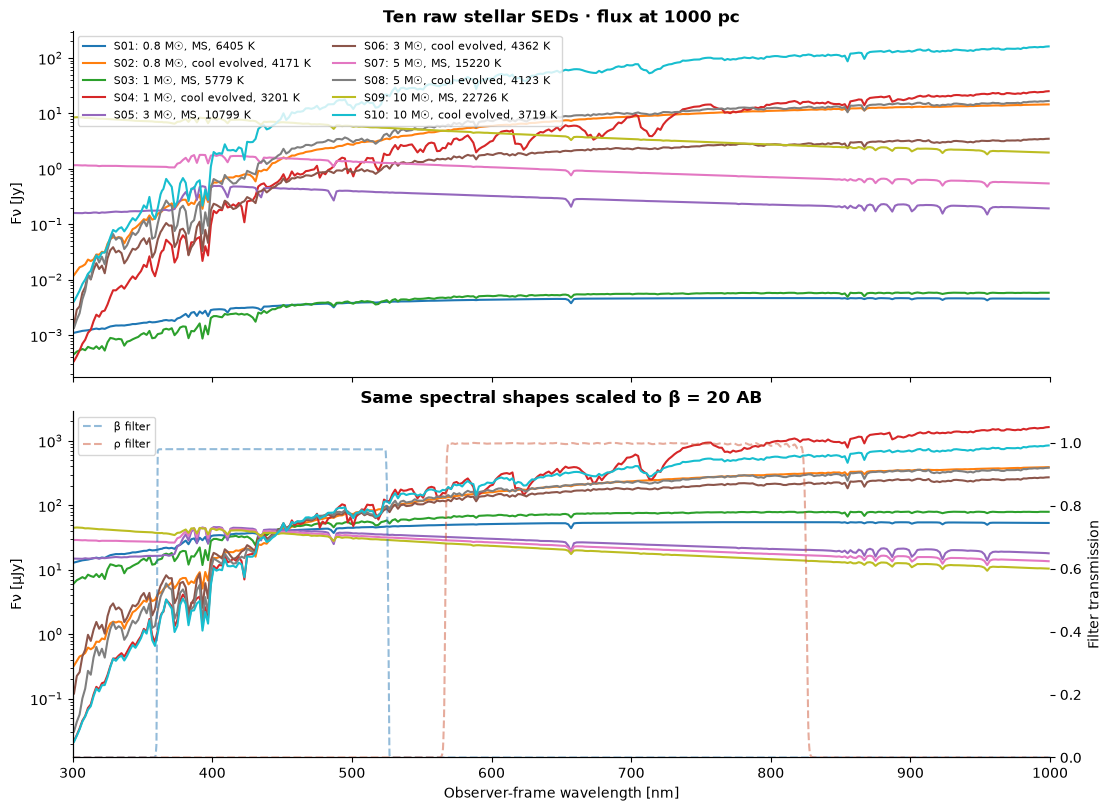

In [6]:
plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False,
                     "figure.facecolor": "white", "axes.titleweight": "bold"})
palette = plt.get_cmap("tab10")

fig, axes = plt.subplots(2, 1, figsize=(11, 8), sharex=True, layout="constrained")
for i, s in enumerate(samples):
    mask = (s["wave"] >= 300 * u.nm) & (s["wave"] <= 1000 * u.nm)
    fnu = s["flux"].to(u.Jy, equivalencies=u.spectral_density(s["wave"]))
    normalized = s["flux20"].to(u.uJy, equivalencies=u.spectral_density(s["wave"]))
    label = f'{s["label"]}: {s["initial_mass_msun"]:g} M☉, {s["state"]}, {s["teff_K"]:.0f} K'
    axes[0].semilogy(s["wave"][mask].to_value(u.nm), fnu[mask].value,
                     color=palette(i), label=label)
    axes[1].semilogy(s["wave"][mask].to_value(u.nm), normalized[mask].value, color=palette(i))
axes[0].set(title=f"Ten raw stellar SEDs · flux at {DISTANCE_PC:g} pc", ylabel="Fν [Jy]")
axes[0].legend(fontsize=8, ncol=2)
axes[1].set(title=f"Same spectral shapes scaled to β = {COMPARISON_BETA_AB:g} AB", ylabel="Fν [µJy]",
            xlabel="Observer-frame wavelength [nm]", xlim=(300, 1000))
response_axis = axes[1].twinx()
for band in BANDS:
    response_axis.plot(tp.wav.value, tp.filt_wav[band], "--", color=COLORS[band],
                       alpha=0.5, label=f"{BAND_LABEL[band]} filter")
response_axis.set(ylabel="Filter transmission", ylim=(0, 1.1))
response_axis.legend(loc="upper left", fontsize=8)
plt.show()

## 7. Inspect AB magnitudes, photon/electron rates, and color

The full-system electron rate differs from the filter-only photon rate because
the system response is weighted by each SED. Cool sources have positive β − ρ
colors (brighter in ρ); hot sources have negative colors. Colors do not depend
on the chosen distance.

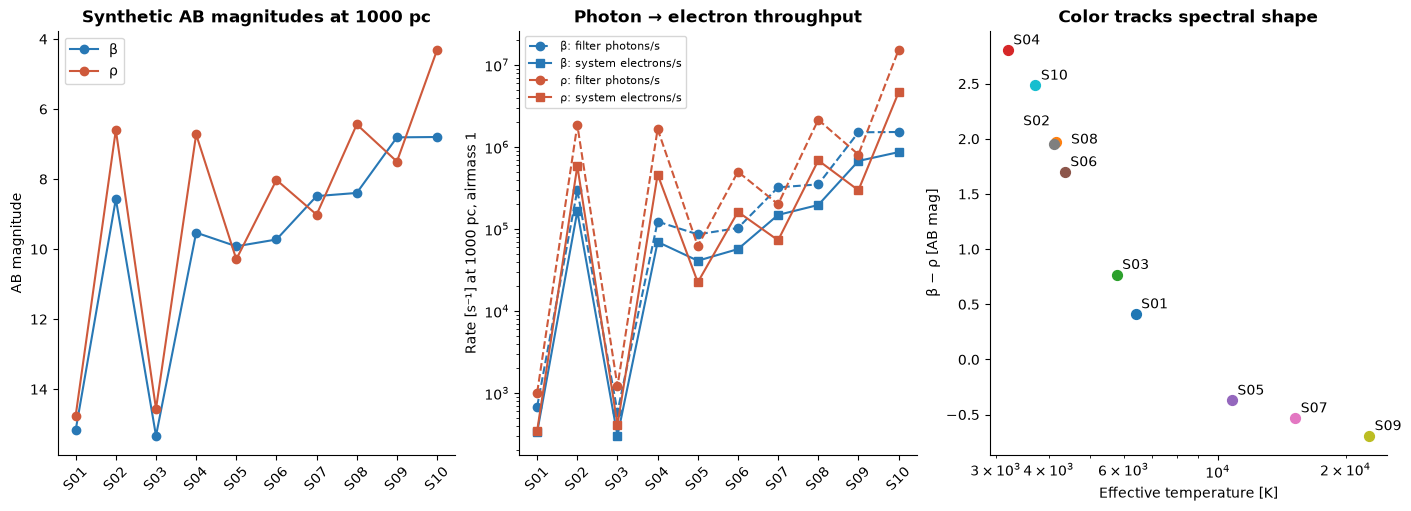

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(14, 5), layout="constrained")
x = np.arange(len(samples))
for band in BANDS:
    rows = [row for row in results if row["band"] == band]
    axes[0].plot(x, [r["mag_ab_at_distance"] for r in rows], "o-", color=COLORS[band], label=BAND_LABEL[band])
    axes[1].semilogy(x, [r["photons_per_s"] for r in rows], "o--", color=COLORS[band],
                     label=f"{BAND_LABEL[band]}: filter photons/s")
    axes[1].semilogy(x, [r["electrons_per_s_am1"] for r in rows], "s-", color=COLORS[band],
                     label=f"{BAND_LABEL[band]}: system electrons/s")
axes[0].invert_yaxis()
axes[0].set(title=f"Synthetic AB magnitudes at {DISTANCE_PC:g} pc", ylabel="AB magnitude")
axes[0].legend()
axes[1].set(title="Photon → electron throughput", ylabel=f"Rate [s⁻¹] at {DISTANCE_PC:g} pc, airmass 1")
axes[1].legend(fontsize=8)
for i, s in enumerate(samples):
    rows = [r for r in results if r["sample"] == s["label"]]
    color = rows[0]["mag_ab_at_distance"] - rows[1]["mag_ab_at_distance"]
    axes[2].scatter(s["teff_K"], color, color=palette(i), s=50)
    offset = {"S02": (-24, 12), "S08": (12, 0)}.get(s["label"], (4, 4))
    axes[2].annotate(s["label"], (s["teff_K"], color), xytext=offset, textcoords="offset points")
for ax in axes[:2]:
    ax.set_xticks(x, [s["label"] for s in samples], rotation=45)
axes[2].set(xscale="log", title="Color tracks spectral shape", xlabel="Effective temperature [K]",
            ylabel="β − ρ [AB mag]")
plt.show()

## 8. Explore SED-dependent atmospheric attenuation

Divide each detected rate by its own airmass-zero rate to isolate atmospheric
attenuation. Zero airmass here means the mathematical no-atmosphere reference.
The dashed flat-Fν AB reference uses the existing `build_band_params` and
`signal_throughput` machinery. Differences between the curves show why a single
flat-spectrum atmosphere correction is not exact for an arbitrary SED.

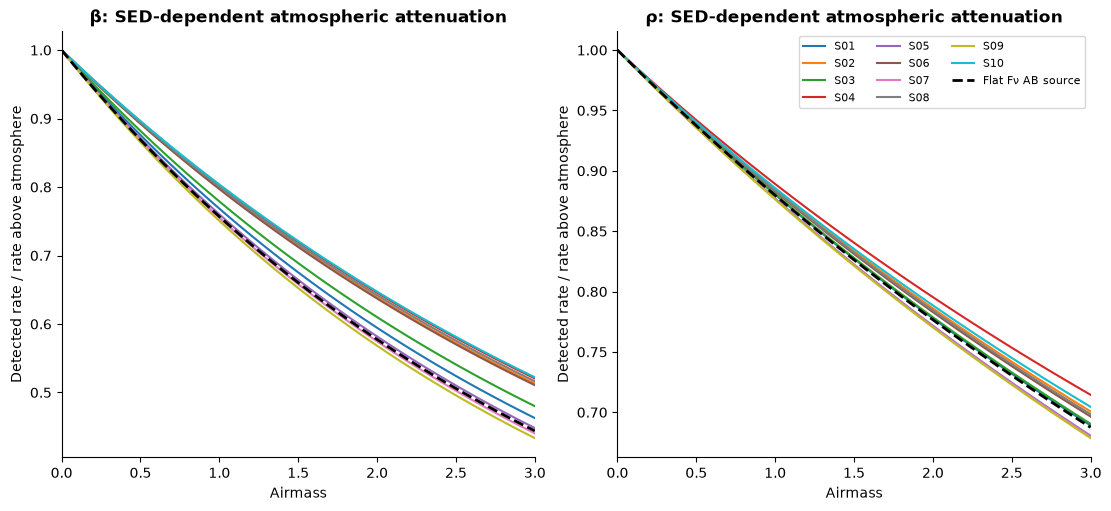

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 5), layout="constrained")
for ax, band in zip(axes, BANDS):
    for i, s in enumerate(samples):
        rate = s["rates"][band]
        ax.plot(airmasses, rate / rate[0], color=palette(i), label=s["label"])
    table = bp[band]
    reference = signal_throughput(table, airmasses) / signal_throughput(table, 0)
    ax.plot(airmasses, reference, "k--", linewidth=2, label="Flat Fν AB source")
    ax.set(title=f"{BAND_LABEL[band]}: SED-dependent atmospheric attenuation", xlabel="Airmass",
           ylabel="Detected rate / rate above atmosphere", xlim=(0, 3))
axes[1].legend(ncol=3, fontsize=8)
plt.show()

## 9. Pass detected electron rates directly into NoiseBudget

To make colors easy to compare, use the spectra normalized to β = 20 AB. Choose
the observational/noise assumptions below, then pass the resulting electron/s
Quantity directly to `get_snr`.

This is an **illustrative noise calculation**, not a survey depth prediction:
sky = 1 e⁻/s/pixel, a normalized Gaussian PSF with σ = 1 pixel, airmass 1.2,
transparency 0.8, read noise 1.7 e⁻, and dark current 0.0022 e⁻/s/pixel.
The larger spread in ρ reflects the different colors at equal β brightness.

In [9]:
coords = np.arange(-5, 6)
xx, yy = np.meshgrid(coords, coords)
psf = np.exp(-(xx**2 + yy**2) / 2)  # Gaussian sigma = 1 pixel
psf /= psf.sum()
noise = NoiseBudget(read_noise=1.7 * u.electron, dark_current=0.0022 * u.electron / u.s)
sky_rate = 1 * u.electron / u.s  # per pixel
source_rate = ab.electrons_from_sed(
    "beta", samples[0]["wave"], samples[0]["flux20"], airmass=1.2, transparency=0.8,
)
snr, budget = noise.get_snr(source_rate, psf, sky_rate, 60 * u.s)
print(f"{samples[0]['label']}, β, 60 s: source = {source_rate:.3f}, SNR = {snr:.3f}")
display(pd.Series(budget, name="Noise budget"))

S01, β, 60 s: source = 2.962 electron / s, SNR = 5.707


sig_flux            2.961791
sky_flux            1.000000
signal            177.707468
noise              31.136818
src_shot           13.330696
sky_shot           27.455896
drk_shot            1.287796
readnoise           6.025720
bkg_only_noise     28.138834
Name: Noise budget, dtype: float64

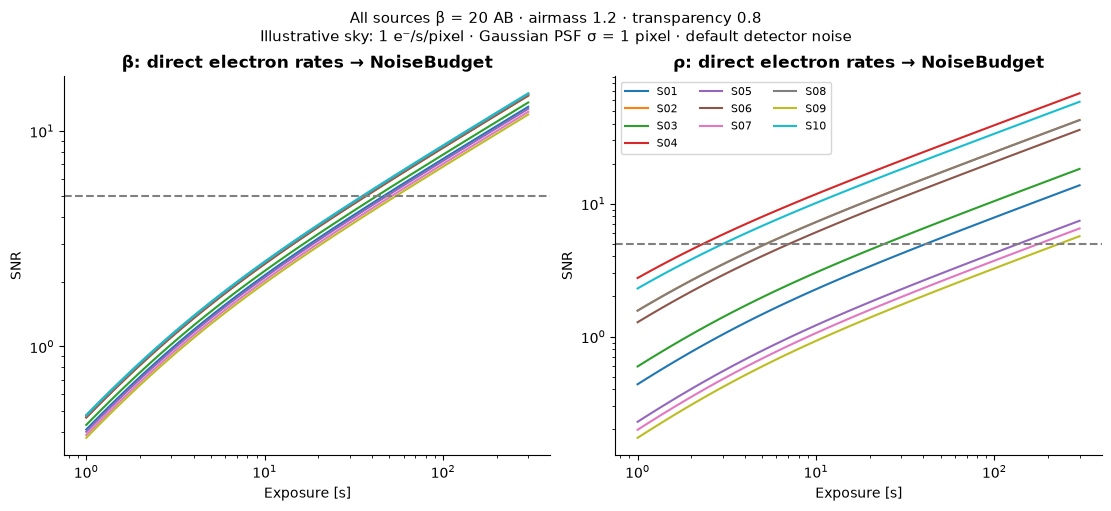

,sample,band,exptime_s,snr
59,S01,β,300.0,12.958
119,S02,β,300.0,14.588
179,S03,β,300.0,13.566
239,S04,β,300.0,14.895
299,S05,β,300.0,12.675
359,S06,β,300.0,14.602
419,S07,β,300.0,12.278
479,S08,β,300.0,14.787
539,S09,β,300.0,11.926
599,S10,β,300.0,14.966


In [10]:
times = np.geomspace(1, 300, 60)
snr_rows = []
fig, axes = plt.subplots(1, 2, figsize=(11, 5), layout="constrained")
for ax, band in zip(axes, BANDS):
    for i, s in enumerate(samples):
        source = ab.electrons_from_sed(band, s["wave"], s["flux20"], airmass=1.2, transparency=0.8)
        snrs = []
        for t in times:
            snr, _ = noise.get_snr(source, psf, sky_rate, t * u.s)
            assert np.isfinite(snr) and snr > 0
            snrs.append(float(snr))
            snr_rows.append(dict(sample=s["label"], band=band, exptime_s=t, snr=float(snr)))
        ax.loglog(times, snrs, color=palette(i), label=s["label"])
    ax.axhline(5, color="0.5", linestyle="--")
    ax.set(title=f"{BAND_LABEL[band]}: direct electron rates → NoiseBudget", xlabel="Exposure [s]", ylabel="SNR")
axes[1].legend(ncol=3, fontsize=8)
fig.suptitle(f"All sources β = {COMPARISON_BETA_AB:g} AB · airmass 1.2 · transparency 0.8\n"
             "Illustrative sky: 1 e⁻/s/pixel · Gaussian PSF σ = 1 pixel · default detector noise", fontsize=11)

plt.show()
snr_table = pd.DataFrame(snr_rows)
display(snr_table.groupby(["sample", "band"]).tail(1).replace({"band": BAND_LABEL}).round(3))

## 10. Check consistency and inspect reusable results

All ten inputs must match their recorded hashes and cover both complete filters.
Equivalent Fλ and Jy inputs should agree; grey transparency should multiply
electron rates; the photon/magnitude and flux-normalization paths should agree;
every SNR must be finite and positive. The errors below are numerical roundoff.

`photometry`, `snr_table`, and the original `samples` Quantity arrays remain in
memory for further analysis. No auxiliary files are created. Photometric fidelity
is still limited by the original atmosphere spectra and their sampling; these
checks validate the interface, not the stellar-atmosphere models themselves.

In [11]:
checks = pd.Series({
    "SEDs processed": len(samples),
    "source-band combinations": len(photometry),
    "full filter coverage": "passed for all ten SEDs in both bands",
    "max relative Fλ/Jy rate error": max(unit_errors),
    "max absolute grey-factor error": max(grey_errors),
    "distance [pc]": DISTANCE_PC,
    "comparison β [AB]": COMPARISON_BETA_AB,
    "collecting area [cm²]": ab.collecting_area.to_value(u.cm**2),
})
assert len(samples) == 10 and len(photometry) == 20
assert len(snr_table) == 10 * 2 * len(times)
display(checks.to_frame("Validation result"))

,Validation result
SEDs processed,10
source-band combinations,20
full filter coverage,passed for all ten SEDs in both bands
max relative Fλ/Jy rate error,0.0
max absolute grey-factor error,0.0
distance [pc],1000.0
comparison β [AB],20.0
collecting area [cm²],394.081382
